# Banknote classification and explanability reimplementation and one alarm method over suspicious text 

Fake Banknote detection is a challenging task among the world, as a prevailing topic in AI in finance. This project will reimplement some existing classifications and explainable AI tools to identiy fake bank note, and use visual explanations to purpose an alarm mechanism over a possible type of missed fake banknote.

**Part 1 · Reimplement and Compare 4 classifiers (Sections 1–7).** Prepare the images, train the models, read each epoch and compare the results on the  test images.

**Part 2 · Review a classification with XAI tools and bridge the gap (Sections 8–11).** Follow a 100-rupee photo that the seed-42 EfficientNetV2-S in Section 6.10 labels Real, implement XAI methods to visualize the Fake score and show the heatmap. Then propose an alarm method over suspocious test to bridge the gap between the classifier and the XAI tool. 

In [78]:
import hashlib
import json
import random
import time
from pathlib import Path
from tempfile import mkdtemp

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import timm
import torch
from IPython.display import display
from matplotlib.figure import Figure
from pytorch_grad_cam import GradCAM, ScoreCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import functional as TF
from torchvision.models import (
    EfficientNet_V2_S_Weights, ResNet18_Weights, efficientnet_v2_s, resnet18,
)

TRAIN_AGAIN = False     # Fit four models with three seeds each.
RUN_DEMOS = False       # Optional short CNN exercise and CAM checkpoint.
RECHECK_RANKING = False # Optional replay of the old/new test comparison.

In [79]:
DATA = Path("dataset_archive_course_v3")
PILOT_DATA = Path("dataset_archive_pilot_v2")
COMPARISON = Path("runs/course_models_archive_v3")
SEED = 42
BATCH_SIZE = 32
DEMO_EPOCHS = 3
EPOCHS = 30
LR = 1e-3
CLASS_NAMES = ["fake money", "OR money", "not a banknote"]
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}
DISPLAY_NAMES = {"fake money": "Fake Money", "OR money": "Real Money", "not a banknote": "Not a Banknote"}
names = [DISPLAY_NAMES[label] for label in CLASS_NAMES]
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
TRANSFER_MODELS = ("resnet18", "efficientnet_v2_s", "dinov3_vits16")
DINO_TIMM_MODEL = "vit_small_patch16_dinov3.lvd1689m"


MODEL_NAMES = {"cnn": "CNN", "resnet18": "ResNet18", "efficientnet_v2_s": "EfficientNetV2-S",
               "dinov3_vits16": "DINOv3 ViT-S/16"}
METRICS = ["accuracy", "balanced_accuracy", "fake_recall", "fake_fnr", "fake_precision",
           "real_false_alarm_rate", "not_banknote_recall", "not_banknote_as_fake_rate"]


def read_rgb(path):
    """Load a photograph as RGB, keeping the stored pixel orientation."""
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR | cv2.IMREAD_IGNORE_ORIENTATION)
    if bgr is None and Path(path).suffix.lower() == ".avif":
        # Some OpenCV builds decode AVIF only through FFmpeg.
        reader = cv2.VideoCapture(str(path), cv2.CAP_FFMPEG)
        _, bgr = reader.read()
        reader.release()
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


# Part 1 · Classifiers

## 1. Image category and dataset

The following part shows the 3 categories for this project: real, fake, and not a bank note. Numbers of test/val/train are shown below with training images and paths as examples. The split and class come directly from the folder names.

Sources: Codebase as references for this project: [Starting repository](https://github.com/barani011/Fake_Money_Detection) ·Dataset of banknotes [Indian currency dataset](https://www.kaggle.com/datasets/preetrank/indian-currency-real-vs-fake-notes-dataset) ·Dataset of non banknotes [Caltech-101 object images](https://data.caltech.edu/records/mzrjq-6wc02)

split,train,val,test
label,,,
Fake Money,83,17,24
Not a Banknote,22,4,4
Real Money,82,17,25


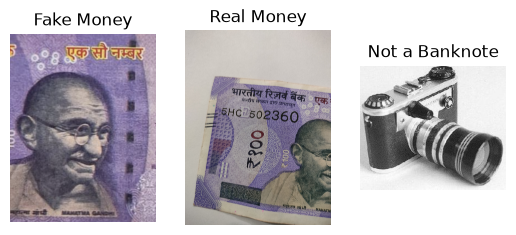

,label,split_path
0,Fake Money,train/fake money/100_32930e5e224a6ac0.png
83,Real Money,train/OR money/100_55b60517387b448b.jpg
165,Not a Banknote,train/not a banknote/camera_image_0044.jpg


In [80]:
def list_images(folder):
    """Return sorted image paths from one class folder so each run visits the same files."""
    extensions = {".jpg", ".jpeg", ".png", ".avif"}
    return [str(p) for p in sorted(Path(folder).iterdir())
            if p.is_file() and p.suffix.lower() in extensions]


def show_photos(files, captions):
    plt.figure()
    for i, (path, caption) in enumerate(zip(files, captions), start=1):
        plt.subplot(1, len(files), i)
        plt.imshow(read_rgb(DATA / path))
        plt.title(caption)
        plt.axis("off")
    plt.show()


rows = []
for split in ("train", "val", "test"):
    for folder, label in DISPLAY_NAMES.items():
        for file in list_images(DATA / split / folder):
            rows.append((split, label, Path(file).relative_to(DATA).as_posix()))

paths = pd.DataFrame(rows, columns=["split", "label", "split_path"])
display(pd.crosstab(paths["label"], paths["split"])[["train", "val", "test"]])

examples = paths[paths["split"] == "train"].drop_duplicates("label")
show_photos(examples["split_path"], examples["label"])
display(examples[["label", "split_path"]])

## 2. Prepare the enviornment and image for the model

First choose the device and set the random seed so the training runs can be repeated.

Sources: **For Sections 2-7** Codes mainly rewrote by building upon the codebase mentioned in Section 1 and Lab work from CSC_51073_EP and CSC_51054_EP (Deep Learning)

In [81]:
def set_seed(seed):
    """Seed the random generators for repeatable training runs."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

All  models use RGB photos resized with padding. The CNN uses 64 × 64 pixels while  Others use 224 × 224 pixels with ImageNet normalization after scaling. The checkpoint records the model name, size and preprocessing separately.

In [82]:
def preprocessing_config(architecture):
    """Record how input images are prepared for this architecture."""
    is_cnn = architecture == "cnn"
    return {
        "img_size": 64 if is_cnn else 224,
        "resize_interpolation": "cv2.INTER_LINEAR",
        "preprocessing": "scale_0_1" if is_cnn else "imagenet_normalized",
    }


**Fit the note into square-cemtered.** Compute the dimensions when squezzing into square centered while keeping the original aspect ratio. The next cell uses OpenCV bilinear interpolation.

In [83]:
def fit_square(original_size, target_size):
    """Resize the long side to target_size and center the image in the square."""
    width, height = original_size
    scale = target_size / max(width, height)
    width = max(1, round(width * scale))
    height = max(1, round(height * scale))
    left = (target_size - width) // 2
    top = (target_size - height) // 2
    return {"resized_w_h": (width, height),
            "resized_coor": (left, top, left + width, top + height)}

**Make the model input.** Convert RGB values to a tensor, normalize the channels for pretrained models, and place the photo on a square canvas. Keep its bounds so the later CAM experiment can exclude the padding.

The resize step uses OpenCV inter linear interpolation. [OpenCV geometric image transformations](https://docs.opencv.org/4.x/da/d54/group__imgproc__transform.html)

In [84]:
class TestTransform:
    """Prepare a full RGB photo for evaluation without cropping it."""
    def __init__(self, architecture="cnn"):
        """Choose the input size and normalization for the selected model."""
        self.size = preprocessing_config(architecture)["img_size"]
        self.normalize = architecture in TRANSFER_MODELS

    def with_geometry(self, image):
        """Return the padded tensor and the photo so CAM can handle padding later."""
        height, width = image.shape[:2]
        geometry = fit_square((width, height), self.size)
        left, top, right, bottom = geometry["resized_coor"]
        # OpenCV expects the new size in (width, height) order.
        rgb = cv2.resize(image, geometry["resized_w_h"], interpolation=cv2.INTER_LINEAR)
        # Convert RGB to a (channels, height, width) tensor in [0, 1].
        pixels = TF.to_tensor(rgb)
        if self.normalize:
            pixels = TF.normalize(pixels, IMAGENET_MEAN, IMAGENET_STD)

        # Place the resized photo inside the square. Padding is zero as input.
        square = pixels.new_zeros((3, self.size, self.size))
        square[:, top:bottom, left:right] = pixels
        return square, geometry

    def __call__(self, image):
        """Return just the image tensor for the dataset loader."""
        return self.with_geometry(image)[0]

**Training only to identify brightness and contrast.** Adjust brightness by scaling the pixels, then adjust contrast around the mean grayscale intensity.([Adjustment algo](https://github.com/pytorch/vision/blob/main/torchvision/transforms/_functional_tensor.py#L13)) Apply the usual resize and padding. Validation and test images skip these random edits.



In [85]:
class TrainAug(TestTransform):
    """Randomly adjust brightness and contrast."""
    def __call__(self, image):
        brightness = random.uniform(0.9, 1.1)
        image = np.clip(image.astype(np.float32) * brightness, 0, 255).astype(np.uint8)

        gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
        center = int(cv2.mean(gray)[0] + 0.5)
        contrast = random.uniform(0.9, 1.1)
        pixels = center + (image.astype(np.float32) - center) * contrast
        return super().__call__(np.clip(pixels, 0, 255).astype(np.uint8))


**Load Dataset.** The dataset stores the paths in order and reads each photo when a training epoch needs it.

In [86]:
class MoneyDataset(Dataset):
    def __init__(self, root, transform=None):
        self.transform = transform or TestTransform()
        self.samples = [(path, label) for label, name in enumerate(CLASS_NAMES)
                        for path in list_images(Path(root) / name)]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, label = self.samples[index]
        return self.transform(read_rgb(path)), label

**Show input.** Dimension as RGB.

In [87]:
photo = read_rgb(DATA / examples.iloc[0]["split_path"])
for architecture in ("cnn", "resnet18"):
    image = TestTransform(architecture)(photo)
    print(MODEL_NAMES[architecture], "input shape:", tuple(image.shape))

CNN input shape: (3, 64, 64)
ResNet18 input shape: (3, 224, 224)


## 3. Build the classifiers

**Start with the CNN.** One 64 × 64 RGB image through 3 convolution and pooling layers. Each pooling halves its width and height with 32 feature maps of  8 × 8. Then the classifier turns them into scores for fake money, real money and non-banknotes.

In [88]:
class FakeMoneyCNN(nn.Module):
    """Classify 64-by-64 RGB photographs using three convolution and pooling layers."""
    def __init__(self, num_classes=3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(32 * 8 * 8, 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

**Build other models.** The CNN trains all its weight. Then build models for ResNet18, EfficnentNetV2-S, and DINOv3.

[ResNet18 builder](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html) · [EfficientNetV2-S builder](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.efficientnet_v2_s.html) · [Exact DINOv3 model card and loading example](https://huggingface.co/timm/vit_small_patch16_dinov3.lvd1689m)

In [89]:
def classification_arch(model):
    """Name of the module trained on the banknote labels."""
    return {"resnet18": "fc", "efficientnet_v2_s": "classifier",
            "dinov3_vits16": "head"}[model.architecture]


def build_model(architecture="cnn", pretrained=False):
    classes = len(CLASS_NAMES)
    if architecture == "cnn":
        model = FakeMoneyCNN(classes)
    elif architecture == "resnet18":
        weights = ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        model = resnet18(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, classes)
    elif architecture == "efficientnet_v2_s":
        weights = EfficientNet_V2_S_Weights.IMAGENET1K_V1 if pretrained else None
        model = efficientnet_v2_s(weights=weights)
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, classes)
    elif architecture == "dinov3_vits16":
        model = timm.create_model(DINO_TIMM_MODEL, pretrained=pretrained, img_size=224, num_classes=0)
        model.head = nn.Linear(model.num_features, classes)

    model.architecture = architecture
    if architecture in TRANSFER_MODELS:
        model.requires_grad_(False)
        getattr(model, classification_arch(model)).requires_grad_(True)
    return model

**Record the initial weights.** The CNN starts from random weights, ResNet18 and EfficientNetV2-S start from ImageNet weights, and DINOv3 uses pretrained transformer weights. Section 4 saves this information with the training run.

In [90]:
def initialization_metadata(architecture):
    """Describe this architecture's training initialization for the experiment record."""
    if architecture == "dinov3_vits16":
        return {"initial_weights": "DINOv3_LVD1689M_timm", "model_variant": DINO_TIMM_MODEL}
    return {"initial_weights": "IMAGENET1K_V1" if architecture in TRANSFER_MODELS else "random",
            "model_variant": architecture}

## 4. Train on batches and select an epoch

**Train for one epoch.** For each batch, predict the 3 class‘ scores, measure cross-entropy loss, and update the  weights. The CNN trains all layers. For the transfer models, train only the head. Average the loss and accuracy.[PyTorch transfer learning tutorial](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html)

In [91]:
def train_one_epoch(model, loader, optimizer, device):
    """Run one pass over the training photos and return mean loss and accuracy."""
    if model.architecture in TRANSFER_MODELS:
        model.eval()
        getattr(model, classification_arch(model)).train()
    else:
        model.train()
    loss_sum, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = nn.functional.cross_entropy(logits, labels)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * len(labels)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += len(labels)
    return loss_sum / total, correct / total

Build metrics with ideas from [confusion metrix](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html). Fake recall counts how many banknotes labelled as fake in the dataset that the model caught. Fake precision counts how many of its fake alerts were correct. The real false alarm rate counts real notes mis-flagged as fake. Others metrics like not_banknote_recall are derived from them.

In [92]:
def classification_metrics(labels, probabilities):
    """Count three-class decisions. Rows are folder labels and columns are predictions."""
    predictions = np.argmax(probabilities, axis=1)
    cm = np.zeros((3, 3), dtype=int)
    np.add.at(cm, (labels, predictions), 1)
    fake, real, other = cm.tolist()
    n_fake, n_real, n_other = cm.sum(axis=1).tolist()
    predicted_fake = int(cm[:, 0].sum())
    recalls = [fake[0] / n_fake, real[1] / n_real, other[2] / n_other]
    return {
        "n": len(labels), "accuracy": int(cm.trace()) / len(labels),
        "balanced_accuracy": sum(recalls) / 3, "confusion_matrix": cm.tolist(),
        "fake_recall": recalls[0], "fake_fnr": (fake[1] + fake[2]) / n_fake,
        "fake_precision": fake[0] / predicted_fake if predicted_fake else None,
        "real_recall": recalls[1], "real_false_alarm_rate": real[0] / n_real,
        "not_banknote_recall": recalls[2], "not_banknote_as_fake_rate": other[0] / n_other,
        "fake_as_real_rate": fake[1] / n_fake, "fake_as_not_banknote_rate": fake[2] / n_fake,
    }

**Evaluate.** Run the model on every batch without updating weights. Average the loss over all images and get the individual probabilities .

In [93]:
@torch.no_grad()
def evaluate(model, loader, device, *, return_predictions=False):
    """Compute split metrics and return labels and probabilities if need prediction."""
    model.eval()
    labels_all, probs_all = [], []
    loss_sum = 0.0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss_sum += nn.functional.cross_entropy(logits, labels, reduction="sum").item()
        labels_all.extend(labels.cpu().tolist())
        probs_all.extend(logits.softmax(dim=1).cpu().tolist())
    metrics = classification_metrics(labels_all, probs_all)
    metrics["loss"] = loss_sum / metrics["n"]
    if return_predictions:
        return metrics, labels_all, probs_all
    return metrics

**Reload a saved model.** A [checkpoint](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html#saving-loading-a-general-checkpoint-for-inference-and-or-resuming-training) contains the architecture name and the learned weights. Here it will be used for recording the best performed epoch later. Build that architecture, load the weights, then switch to evaluation mode. Return the checkpoint too so later cells can read the selected epoch and its validation scores.

In [94]:
def load_checkpoint(path, device):
    """Load a three-class course checkpoint and switch the classifier to evaluation mode."""
    checkpoint = torch.load(path, map_location=device, weights_only=True)
    model = build_model(checkpoint["architecture"]).to(device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()
    return model, checkpoint


**Prepare a training run**: Shuffle the training photos for augumenting the model when next run. Keep validation photos in a fixed order. Save the model and image settings with each checkpoint so the weights can be [loaded](https://docs.pytorch.org/docs/2.15/data.html#torch.utils.data.DataLoader) later.

In [95]:
def training_loaders(data_dir, architecture, batch_size, seed):
    root = Path(data_dir)
    train_images = MoneyDataset(root / "train", transform=TrainAug(architecture))
    val_images = MoneyDataset(root / "val", transform=TestTransform(architecture))
    shuffle_order = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(train_images, batch_size=batch_size, shuffle=True, generator=shuffle_order)
    val_loader = DataLoader(val_images, batch_size=batch_size)
    return train_loader, val_loader


def checkpoint_settings(architecture, seed, batch_size, data_dir):
    return {
        "architecture": architecture, "seed": seed, "batch_size": batch_size,
        **preprocessing_config(architecture), **initialization_metadata(architecture),
        "class_to_idx": CLASS_TO_IDX, "resize_mode": "letterbox", "decision_rule": "argmax",
        "training_mode": "frozen_backbone_head_only" if architecture in TRANSFER_MODELS else "all_parameters",
        "learning_rate": LR, "fake_threshold": 0.5, "selection_metric": "val_loss",
        "data_dir": str(Path(data_dir).resolve()),
    }

**Train, validate, then keep the best epoch.** Each pass adds one row to the training history. Save the model when validation loss crosses minimum. Stop after the chosen number of epochs without improvement, then return the saved model. Section 5 reads the epoch records.

In [96]:
def train(epochs, data_dir, output_dir,device, seed, architecture ):
    """Fit one model and return its best validation checkpoint as a model, plus its history."""
    set_seed(seed)
    patience=8
    batch_size=BATCH_SIZE
    train_loader, val_loader = training_loaders(data_dir, architecture, batch_size, seed)
    model = build_model(architecture, pretrained=architecture in TRANSFER_MODELS).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    folder = Path(output_dir or f"runs/threeclass_{architecture}_letterbox")
    folder.mkdir(parents=True, exist_ok=True)
    checkpoint = folder / "best.pt"
    settings = checkpoint_settings(architecture, seed, batch_size, data_dir)
    records = []
    best_loss, best_epoch = float("inf"), 0
    started = time.perf_counter()

    for epoch in range(1, epochs + 1):
        loss, accuracy = train_one_epoch(model, train_loader, optimizer, device)
        val = evaluate(model, val_loader, device)
        records.append({"epoch": epoch, "train_loss": loss, "train_accuracy": accuracy, "val": val})
        print(f"Epoch {epoch}/{epochs}  train loss {loss:.4f}  val loss {val['loss']:.4f}  "
              f"fake recall {val['fake_recall']:.3f}  real false alarm {val['real_false_alarm_rate']:.3f}")

        if val["loss"] < best_loss:
            best_loss, best_epoch = val["loss"], epoch
            torch.save({**settings, "epoch": epoch, "val_metrics": val,
                        "model_state_dict": model.state_dict()}, checkpoint)
        if epoch - best_epoch >= patience:
            print(f"Early stopping at epoch {epoch}")
            break

    history = {key: settings[key] for key in ("architecture", "seed", "batch_size", "preprocessing", "resize_mode")}
    history.update(epochs=records, device=str(device), training_seconds=time.perf_counter() - started)
    (folder / "history.json").write_text(json.dumps(history, indent=2))
    best_model, _ = load_checkpoint(checkpoint, device)
    print(f"Best epoch {best_epoch}: {checkpoint}")
    return best_model, history

## 5. Train the models and read the epoch logs

Run each model with seeds 42, 43 and 44 for [reproducibility](https://docs.pytorch.org/docs/2.15/notes/randomness.html). When needs re-training, TRAIN_AGAIN=true. When just skipping to see results of previous run, it opens the run folder trained before and proceed.


In [97]:
seeds = [42, 43, 44]
archs = list(MODEL_NAMES)
device = get_device()
torch.set_num_threads(2)

if TRAIN_AGAIN:
    run_root = Path(mkdtemp(prefix="course_models_", dir=COMPARISON.parent))
    print("Writing new training runs to", run_root)
    for arch in archs:
        for seed in seeds:
            folder = run_root / arch / f"seed_{seed}"
            train(EPOCHS, DATA, folder, device=device, seed=seed, architecture=arch)
else:
    run_root = COMPARISON
    print("Reading recorded training runs from", run_root)


Reading recorded training runs from runs/course_models_archive_v3


**Follow each run from its first epoch to its last**: Each table below follows 1 model and 1 seed. Read the training loss column downward to see changes. Then find the lowest validation loss. The star marks the checkpoint for testing. For example,  the recorded CNN run with seed 42, epoch 19 was selected and training continued through epoch 27.


In [98]:
runs = []
for arch in archs:
    for seed in seeds:
        folder = run_root / arch / f"seed_{seed}"
        history = json.loads((folder / "history.json").read_text())
        epochs = history["epochs"]
        best = min(epochs, key=lambda row: row["val"]["loss"])
        print(f"{MODEL_NAMES[arch]} | seed {seed} | selected epoch {best['epoch']}")
        rows = []
        for row in epochs:
            rows.append({"Epoch": row["epoch"], "Train loss": row["train_loss"],
                         "Train acc": row["train_accuracy"], "Val loss": row["val"]["loss"],
                         "Val acc": row["val"]["accuracy"], "Val fake recall": row["val"]["fake_recall"],
                         "Val real false alarm": row["val"]["real_false_alarm_rate"],
                         "Selected": "*" if row["epoch"] == best["epoch"] else ""})
        display(pd.DataFrame(rows).set_index("Epoch").round(4))
        runs.append({"architecture": arch, "seed": seed, "best_epoch": best["epoch"],
                     "training_seconds": history["training_seconds"],
                     "checkpoint": str((folder / "best.pt").relative_to(run_root))})


CNN | seed 42 | selected epoch 19


,Train loss,Train acc,Val loss,Val acc,Val fake recall,Val real false alarm,Selected
Epoch,,,,,,,
1,1.0708,0.4439,1.0047,0.4474,1.0000,1.0000,
2,0.9863,0.5027,0.9807,0.4474,0.0000,0.0000,
3,0.9945,0.4385,0.9666,0.6053,0.8824,0.5294,
4,0.9700,0.5027,0.9585,0.4474,1.0000,1.0000,
5,0.9590,0.5294,0.9382,0.6579,0.5882,0.1176,
6,0.9363,0.6203,0.8991,0.6316,0.8235,0.4118,
7,0.8782,0.6417,0.8484,0.6316,0.8235,0.4118,
8,0.8207,0.6310,0.8093,0.5789,0.7059,0.4118,
9,0.7931,0.6524,0.7874,0.6842,0.7647,0.2353,


CNN | seed 43 | selected epoch 15


,Train loss,Train acc,Val loss,Val acc,Val fake recall,Val real false alarm,Selected
Epoch,,,,,,,
1,1.0585,0.3583,0.9851,0.4474,1.0000,1.0000,
2,0.9839,0.4439,0.9719,0.4474,1.0000,1.0000,
3,0.9743,0.4545,0.9640,0.6053,0.7647,0.4118,
4,0.9584,0.4759,0.9480,0.6053,0.8235,0.4706,
5,0.9283,0.6417,0.9293,0.6316,0.7647,0.3529,
6,0.8984,0.6043,0.8754,0.6053,0.8235,0.4706,
7,0.8314,0.6417,0.8329,0.6053,0.8235,0.4706,
8,0.8110,0.6471,0.8310,0.6316,0.5294,0.1176,
9,0.7461,0.6684,0.7892,0.6579,0.8824,0.4118,


CNN | seed 44 | selected epoch 23


,Train loss,Train acc,Val loss,Val acc,Val fake recall,Val real false alarm,Selected
Epoch,,,,,,,
1,1.0289,0.4439,0.9919,0.4474,1.0000,1.0000,
2,1.0019,0.4278,0.9761,0.4474,0.0000,0.0000,
3,0.9935,0.4385,0.9948,0.4474,0.0000,0.0000,
4,0.9895,0.4385,0.9606,0.4474,0.0000,0.0000,
5,0.9557,0.4920,0.9477,0.5000,1.0000,0.8824,
6,0.9338,0.5936,0.9171,0.6316,0.7647,0.3529,
7,0.8889,0.6364,0.8716,0.6316,0.8235,0.4118,
8,0.8510,0.6524,0.8550,0.6579,0.7647,0.2941,
9,0.7863,0.6845,0.8019,0.6316,0.8235,0.4118,


... (14 outputs left out)

DINOv3 ViT-S/16 | seed 43 | selected epoch 30


,Train loss,Train acc,Val loss,Val acc,Val fake recall,Val real false alarm,Selected
Epoch,,,,,,,
1,1.0771,0.3957,0.9827,0.5000,0.5882,0.4706,
2,0.9323,0.6043,0.8827,0.5000,0.5882,0.4706,
3,0.8530,0.6524,0.8243,0.6579,0.7059,0.2353,
4,0.7981,0.7005,0.7851,0.6579,0.7059,0.2353,
5,0.7567,0.7326,0.7536,0.6842,0.7059,0.1765,
6,0.7205,0.7326,0.7255,0.6842,0.7059,0.1765,
7,0.6867,0.7326,0.7015,0.6842,0.7059,0.1765,
8,0.6559,0.7594,0.6767,0.6842,0.7059,0.1765,
9,0.6275,0.7701,0.6542,0.7368,0.7647,0.1765,


DINOv3 ViT-S/16 | seed 44 | selected epoch 30


,Train loss,Train acc,Val loss,Val acc,Val fake recall,Val real false alarm,Selected
Epoch,,,,,,,
1,0.9763,0.5348,0.9163,0.5789,0.6471,0.3529,
2,0.8897,0.6578,0.8523,0.6579,0.8235,0.3529,
3,0.8290,0.6898,0.8097,0.7105,0.8235,0.2353,
4,0.7818,0.7326,0.7748,0.7368,0.8235,0.1765,
5,0.7421,0.7487,0.7433,0.7368,0.8235,0.1765,
6,0.7042,0.7647,0.7158,0.7368,0.8235,0.1765,
7,0.6684,0.7701,0.6902,0.7368,0.8235,0.1765,
8,0.6382,0.7701,0.6657,0.7632,0.8235,0.1765,
9,0.6084,0.7807,0.6442,0.7632,0.8235,0.1765,


## 6. Compare models

The CNN learns from 64 × 64 images. ResNet18, EfficientNetV2-S and DINOv3 train a classification on 224 × 224. All use squre scale, Adam optimizer, the same set of images and a 30 epoch run limit. The lowest validation loss selects each checkpoint.

Each selected checkpoint is evaluated on the same 53 test images. The dataset labels 24 as fake, 25 as real and 4 as non-banknotes.

| Table column | How to read it |
| --- | --- |
| Accuracy | Out of all 53 images, what percentage got the correct label? Higher is better. |
| Fake recall | Out of the 24 images labelled fake, what percentage did the model catch? Higher is better. |
| Missed fakes | Out of the 24 images labelled fake, what percentage did the model call real or non-banknote? This is 100% minus fake recall. Lower is better. |
| Real flagged fake | Out of the 25 images labelled real, what percentage did the model call fake? Lower means fewer false alarms. |
| Fake precision | For all the images the model called fake, what percentage had a fake label in the dataset? Higher means a fake alert is more often correct. |
| Seconds per fit | Average time in seconds to train the model once. A smaller number means faster training. |

For example, in the recorded EfficientNetV2-S run with seed 42, the model caught 23 of the 24 fake-labelled images. It also flagged 4 real-labelled images. Its fake recall was 23/24 (95.8%), and its fake precision was 23/27 (85.2%).

The table averages three training runs with seeds 42, 43 and 44. A fake recall of 93.1 ± 2.4% means the average was 93.1% and the sample standard deviation across runs was 2.4 percentage points. A smaller spread means the runs gave more similar results on these images.

In the plots below, validation loss measures how well the predicted probabilities fit the validation labels (lower is better). Non-banknote recall is the percentage of the 4 non-banknote test images correctly identified. In each confusion matrix, read across a row for a dataset label and down a column for a prediction. For example, the Real row and Fake column shows false alarms.

### 6.1 Make the result persistent for re-train

For each photo, record its file path, folder label and predicted class. Keeping the test images in order lets us find the exact photo behind a missed fake or a false alarm.

In [99]:
def evaluate_split(model, dataset, device, batch_size):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    metrics, labels, probabilities = evaluate(model, loader, device, return_predictions=True)
    rows = []
    for (path, _), label, probs in zip(dataset.samples, labels, probabilities):
        rows.append({"path": path, "true_label": label, "predicted_label": int(np.argmax(probs)),
                     "probabilities": probs, "p_fake": probs[0], "p_real": probs[1]})
    return metrics, rows

### 6.2 Summarize each metric across seeds

Read down one metric column. Report the average, sample standard deviation and number of available scores. A single score gives an average but no sample standard deviation.

In [100]:
def metric_summary(table):
    """Summarize each metric across seeds, skipping missing scores."""
    summary = {}
    for name in METRICS:
        values = table[name].dropna().astype(float)
        count = len(values)
        summary[name] = {
            "mean": values.mean() if count else None,
            "sd": values.std() if count > 1 else None,
            "defined_runs": count,
        }
    return summary

### 6.3 Compare models trained with the same seed

Compare validation and test separately. For each model, subtract the baseline score for the matching seed, then average those differences. Multiplying by 100 expresses the gap in percentage points.

In [101]:
def summarize(results):
    summary = {}
    for split in ("val", "test"):
        # Each row is one training run. The index pairs runs with the same seed.
        rows = [{"model": run["architecture"], "seed": run["seed"], **run[split]}
                for run in results["runs"]]
        runs = pd.DataFrame(rows, columns=["model", "seed", *METRICS]).set_index("seed")
        scores = {model: runs.loc[runs["model"] == model, METRICS]
                  for model in results["protocol"]["models"]}
        table = {model: metric_summary(frame) for model, frame in scores.items()}

        gaps = {}
        for model, frame in scores.items():
            for baseline in ("cnn", "resnet18"):
                if baseline in scores and model != baseline:
                    difference = 100 * (frame - scores[baseline])
                    gaps[f"{model}_minus_{baseline}"] = metric_summary(difference)
        table["paired_deltas_percentage_points"] = gaps
        summary[split] = table
    return summary

### 6.4 [Plot](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.plot.html) validation loss and test scores

At 6.9, The left panel shows one validation loss curve per run. The right panel compares 4 test metrics. Bar height is the seed average and error bars show the standard deviation.

In [102]:
def plot_comparison(results, output):
    """Plot validation loss and test scores."""
    fig = Figure(figsize=(13, 5))
    left, right = fig.subplots(1, 2)

    for run in results["runs"]:
        model, seed = run["architecture"], run["seed"]
        path = output / model / f"seed_{seed}" / "history.json"
        epochs = json.loads(path.read_text())["epochs"]
        left.plot([e["epoch"] for e in epochs], [e["val"]["loss"] for e in epochs],
                  label=f"{MODEL_NAMES[model]} / {seed}")
    left.set(xlabel="Epoch", ylabel="Validation loss")
    left.legend(fontsize=7)

    metrics = ["accuracy", "fake_recall", "real_false_alarm_rate", "not_banknote_recall"]
    means, errors = {}, {}
    for model in results["protocol"]["models"]:
        scores = pd.DataFrame(results["summary"]["test"][model]).T.loc[metrics]
        means[MODEL_NAMES[model]] = scores["mean"] * 100
        errors[MODEL_NAMES[model]] = scores["sd"].fillna(0) * 100
    pd.DataFrame(means).plot.bar(ax=right, yerr=pd.DataFrame(errors), rot=15)
    right.set_xticklabels(["Accuracy", "Fake recall", "Real false alarm", "Non-banknote recall"])
    right.set_ylabel("Test score (%)")
    fig.tight_layout()
    fig.savefig(output / "comparison.png", dpi=160)

### 6.5 Plot the confusion matrices

At 6.9, average the 3 confusion matrices for each model. The Fake row and Real column count missed notes labelled as fake but classified as real.

In [103]:
def plot_confusion_matrices(results, output):
    models = results["protocol"]["models"]
    names = ["Fake", "Real", "Non-banknote"]
    fig = Figure(figsize=(4 * len(models), 4))
    axes = fig.subplots(1, len(models), squeeze=False)
    for ax, arch in zip(axes[0], models):
        cm = np.mean([r["test"]["confusion_matrix"] for r in results["runs"] if r["architecture"] == arch], axis=0)
        ax.imshow(cm, cmap="Blues", vmin=0)
        for (i, j), value in np.ndenumerate(cm):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center")
        ax.set(xticks=range(len(cm)), yticks=range(len(cm)), xticklabels=names, yticklabels=names,
               xlabel="Predicted", ylabel="True", title=MODEL_NAMES[arch])
    fig.suptitle("Test confusion matrices")
    fig.tight_layout()
    fig.savefig(output / "confusion_matrices.png", dpi=160)

### 6.6 Save the comparison files

Keep per-image predictions in JSON, one row per training run in CSV, and the two figures alongside them.

In [104]:
def save_comparison(results, output):
    """Save the per-seed measurements, summary statistics and comparison figures."""
    results["summary"] = summarize(results)
    (output / "comparison.json").write_text(json.dumps(results, indent=2))
    rows = []
    for run in results["runs"]:
        row = {"model": run["architecture"], "seed": run["seed"], "best_epoch": run["best_epoch"],
               "training_seconds": run["training_seconds"]}
        for split in ("val", "test"):
            row.update({f"{split}_{metric}": run[split].get(metric) for metric in METRICS})
        rows.append(row)
    pd.DataFrame(rows).to_csv(output / "comparison.csv", index=False)
    plot_comparison(results, output)
    plot_confusion_matrices(results, output)

### 6.7 Load or calculate the comparison

The default reads the archived comparison. And with `TRAIN_AGAIN` enabled, score each newly selected checkpoint on validation and test images and save the results in the new run folder.

In [105]:
if TRAIN_AGAIN:
    for run in runs:
        model, _ = load_checkpoint(run_root / run["checkpoint"], device)
        transform = TestTransform(model.architecture)
        for split in ("val", "test"):
            dataset = MoneyDataset(DATA / split, transform=transform)
            run[split], run[split + "_predictions"] = evaluate_split(model, dataset, device, BATCH_SIZE)
    protocol = dict(models=archs, seeds=seeds, class_to_idx=CLASS_TO_IDX, epochs=EPOCHS,
                    batch_size=BATCH_SIZE, learning_rate=LR, selection_metric="val_loss", device=str(device))
    results = {"protocol": protocol, "runs": runs}
    save_comparison(results, run_root)
else:
    results = json.loads((run_root / "comparison.json").read_text())

### 6.8 Metric Table

Show the metrics on table for each model.

In [106]:
metrics = {"accuracy":"Accuracy", "fake_recall":"Fake recall", "fake_fnr":"Missed fakes",
           "real_false_alarm_rate":"Real flagged fake", "fake_precision":"Fake precision"}
seconds = pd.DataFrame(results["runs"]).groupby("architecture")["training_seconds"].mean()
table = []
for arch in archs:
    row = {"Model": MODEL_NAMES[arch]}
    scores = results["summary"]["test"][arch]
    for key, title in metrics.items():
        stat = scores[key]
        mean, sd = stat["mean"], stat["sd"]
        row[title] = "n/a" if mean is None else f"{mean:.1%}"
        if sd is not None:
            row[title] = f"{100 * mean:.1f} ± {100 * sd:.1f}%"
    row["Seconds per fit"] = round(seconds[arch], 1)
    table.append(row)
display(pd.DataFrame(table).set_index("Model"))

,Accuracy,Fake recall,Missed fakes,Real flagged fake,Fake precision,Seconds per fit
Model,,,,,,
CNN,78.0 ± 2.9%,86.1 ± 2.4%,13.9 ± 2.4%,29.3 ± 8.3%,71.6 ± 4.8%,70.3
ResNet18,86.8 ± 3.3%,88.9 ± 8.7%,11.1 ± 8.7%,17.3 ± 2.3%,83.1 ± 1.3%,95.5
EfficientNetV2-S,90.6 ± 0.0%,93.1 ± 2.4%,6.9 ± 2.4%,13.3 ± 2.3%,87.1 ± 1.6%,137.8
DINOv3 ViT-S/16,89.9 ± 1.1%,91.7 ± 0.0%,8.3 ± 0.0%,13.3 ± 2.3%,86.9 ± 2.0%,127.9


### 6.9 Display results

Show 6.4 and 6.5 plots

/Users/grz/Documents/dataai/CSC_51073_EP/project/Fake_Money_Detection/runs/course_models_archive_v3/comparison.png


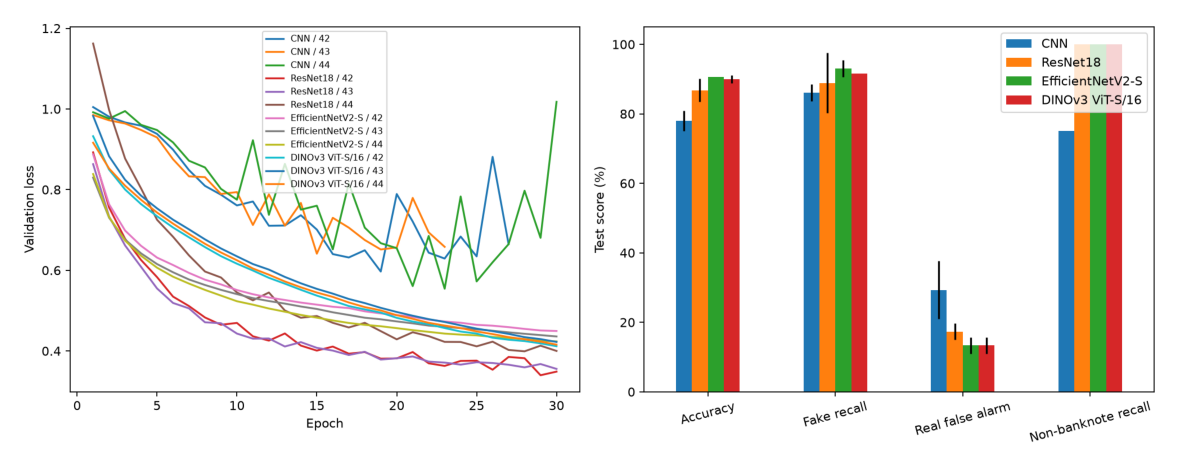

/Users/grz/Documents/dataai/CSC_51073_EP/project/Fake_Money_Detection/runs/course_models_archive_v3/confusion_matrices.png


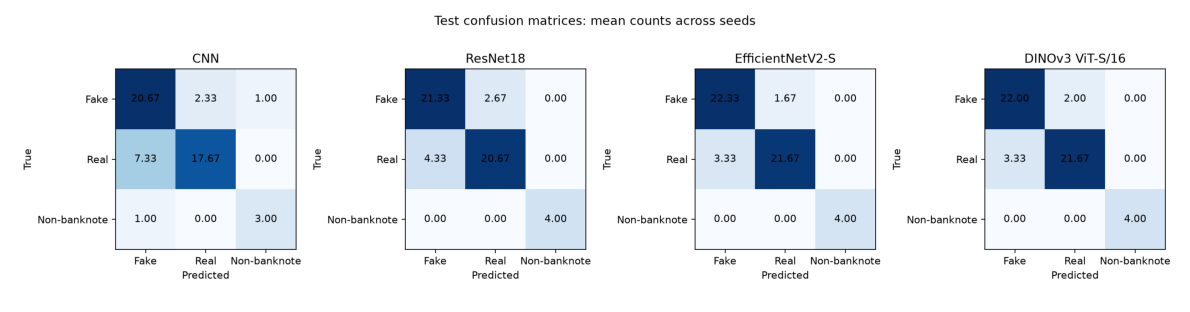

In [107]:
for name in ("comparison.png", "confusion_matrices.png"):
    path = run_root / name
    print(path.resolve())
    plt.figure(figsize=(12, 5))
    plt.imshow(read_rgb(path))
    plt.axis("off")
    plt.tight_layout()
    plt.show()

### 6.10 Conclude the result

In the metrics table, EfficientNetV2-S has about **4 percentage points in fake recall** over ResNet18 and lowered the real-note false-alarm rate by about **4**. For DINOv3 its recall was about **1.5** lower than EfficientNetV2-S. 


**Overall EfficientNetV2-S is the best here.**


**And here's an interesting observation: Can two models have very similar accuracy but missing different notes?** Use seed 42, where the recorded EfficientNet and DINOv3 runs both got 48 of 53 right. The left panel shows the first note labelled as fake that EfficientNet caught and DINOv3 missed. The second shows the reverse. Use the image paths to find the examples in the dataset folder, the table below also shows the CNN and ResNet18 predictions for the first six errors across the four models.

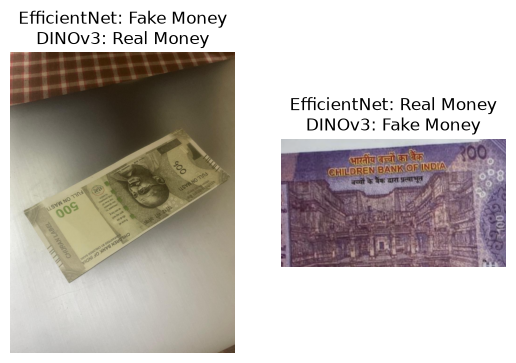

,label,EfficientNetV2-S,DINOv3 ViT-S/16
split_path,,,
test/fake money/500_12ede66445aa3822.jpg,Fake Money,Fake Money,Real Money
test/fake money/100_4b6f91bfcd036823.png,Fake Money,Real Money,Fake Money


,label,CNN,ResNet18,EfficientNetV2-S,DINOv3 ViT-S/16
split_path,,,,,
test/fake money/100_4b6f91bfcd036823.png,Fake Money,Fake Money,Fake Money,Real Money,Fake Money
test/fake money/2000_6ed5ae16eb6d0ce8.png,Fake Money,Not a Banknote,Fake Money,Fake Money,Fake Money
test/fake money/500_12ede66445aa3822.jpg,Fake Money,Real Money,Fake Money,Fake Money,Real Money
test/fake money/500_92c7017763de5a1b.jpg,Fake Money,Real Money,Real Money,Fake Money,Fake Money
test/fake money/500_c8ec7e37f9739637.jpg,Fake Money,Fake Money,Fake Money,Fake Money,Real Money
test/OR money/100_f5a765f1ce4bb123.jpg,Real Money,Fake Money,Real Money,Real Money,Real Money


In [108]:
cases = paths.loc[paths["split"] == "test", ["split_path", "label"]].set_index("split_path")
for run in results["runs"]:
    if run["seed"] == 42:
        predictions = {}
        for photo in run["test_predictions"]:
            file = Path(photo["path"])
            predictions[f"test/{file.parent.name}/{file.name}"] = names[photo["predicted_label"]]
        cases[MODEL_NAMES[run["architecture"]]] = predictions

# Show one fake note caught only by EfficientNet and one caught only by DINOv3 in this pair.
fake = cases.loc[cases["label"] == "Fake Money", ["label", "EfficientNetV2-S", "DINOv3 ViT-S/16"]]
efficient = fake["EfficientNetV2-S"] == "Fake Money"
dino = fake["DINOv3 ViT-S/16"] == "Fake Money"
# boolean indexing: https://pandas.pydata.org/docs/user_guide/indexing.html#boolean-indexing
pair = pd.concat([fake[efficient & ~dino].head(1), fake[dino & ~efficient].head(1)])
if not pair.empty:
    show_photos(pair.index, "EfficientNet: " + pair["EfficientNetV2-S"] + "\nDINOv3: " + pair["DINOv3 ViT-S/16"])
display(pair)

# Show the first six photos that at least one model got wrong.
predictions = cases[[MODEL_NAMES[arch] for arch in archs]]
wrong = predictions.ne(cases["label"], axis="index").any(axis=1)
display(cases.loc[wrong, ["label", *predictions.columns]].head(6))

## 7. Can a different test set change which model wins?

Read the last two columns first. They evaluate the same expanded-data checkpoints on two sets of photographs: the old test set (12 images, four per class) and the expanded test set (53 images). The table reports mean accuracy across seeds 42, 43 and 44. Four non-banknote photos appear in both sets. The first column gives the earlier training run for context. [Historical log](runs/course_models_archive_v3/rank_check/original_four_model_run.log) · [Fixed-checkpoint predictions](runs/course_models_archive_v3/rank_check/fixed_checkpoint_test.json)

In [ ]:
rank_dir = COMPARISON / "rank_check"
rank = json.loads((rank_dir / "fixed_checkpoint_test.json").read_text())
accuracy = pd.DataFrame({
    "Original set → old test": {m: rank["historical"][m]["accuracy"]["mean"] for m in archs},
    "Expanded set → old test": {m: rank["fixed_checkpoint_means"][m]["old"]["accuracy"] for m in archs},
    "Expanded set → new test": {m: rank["fixed_checkpoint_means"][m]["new"]["accuracy"] for m in archs}})
display((100 * accuracy.rename(index=MODEL_NAMES)).round(2).rename_axis("Accuracy (%)"))


,Original set → old test,Expanded set → old test,Expanded set → new test
Accuracy (%),,,
CNN,55.56,77.78,77.99
ResNet18,83.33,63.89,86.79
EfficientNetV2-S,80.56,66.67,90.57
DINOv3 ViT-S/16,88.89,61.11,89.94


### 7.1 What changed when only the test images changed?

The small CNN won on the old test set (77.78% accuracy versus 66.67% for EfficientNetV2-S). But with the same weights, EfficientNet won on the expanded test set (90.57% versus 77.99% for the CNN). This gives a concrete example of the winner changing with the test set. The old set was small enough that one moved a single run’s accuracy by 8.33 percentage points. The expanded set also gives more weight to 500- and 2000-rupee photos (44 of 53 images). These comparisons measure the combined effect of changing the images and their mix of rupee types.

DINOv3 won in the original training run (88.89%, first column). With the expanded checkpoints fixed, EfficientNet scored above DINOv3 on both test sets. On the expanded test, their difference amounts to one correct decision across 3 runs on the same 53 photos.

### 7.2 Results cannot be explained so far

Section 6.10 shows two test images labelled Fake. Both carry the words *CHILDREN BANK OF INDIA*, but the models disagreed in opposite directions.

| Photo | EfficientNetV2-S | DINOv3 ViT-S/16 |
|---|---|---|
| 500 rupees, tilted note on a tabletop | Fake (84.1%) | Real (69.8%) |
| 100 rupees, close view of the printed design | Real (63.9%) | Fake (66.1%) |

Percentages are the scores assigned to the winning class. On the 500-rupee photo the portrait is upside down, the lettering is small and angled, and much of the frame shows the table. On the 100-rupee photo the toy-bank wording is upright near the top. At the same  input size the two images give quite different views of the lettering and note design. One possible explanation is that the two pretrained models give different weight to layout, lettering, projection or background. The predictions establish the disagreement; they cannot identify which clues of the bank note caused it identify as fake/real.

**From a wrong label to a question.** Imagine reviewing the 100-rupee photo. The toy-bank wording gives us a reason to question a Real prediction. But did the model respond to those letters, or to another part of the image? Even a correct Fake prediction leaves this question open. Testing why EfficientNet and DINOv3 disagreed would require examining each of those trained models on the same input.

**Part 2 follows one decision.** We examine the seed-42 EfficientNetV2-S on that same 100-rupee photo. First we map its response for the Fake class. Then we use OCR to read the visible wording and measure how the Fake probability changes when we blur that line. This gives a reviewer a concrete reason to recheck a Real prediction.

# Part 2 · Review a possible missed fake

EfficientNetV2-S caught the most fake-labelled notes on average in Part 1. However, that does not mean for every countries suffering from fake bank notes, let a software engineer program a detection software using EfficientNetV2-S is enough. In Section 6.10 it makes a very "stupid" mistake of not seeing the "CHILDREN" text on the note. Thus, this will be used as the case study example to examine a supplementary method with XAI to help mitigate. 

Sections 8–10 show the prediction, compare two heatmaps for the Fake class and test their pixel rankings. Section 11 gives the model decision to a reviewer to bridge the gap between the model and XAI techniques as an alarm.

For existing XAI methodds, [Grad-CAM](https://openaccess.thecvf.com/content_iccv_2017/html/Selvaraju_Grad-CAM_Visual_Explanations_ICCV_2017_paper.html)  weights feature maps using gradients of the target score. [Score-CAM](https://openaccess.thecvf.com/content_CVPRW_2020/html/w1/Wang_Score-CAM_Score-Weighted_Visual_Explanations_for_Convolutional_Neural_Networks_CVPRW_2020_paper.html) estimates weights by scoring masked inputs.

## 8. Which class did EfficientNetV2-S choose?

Before looking at a heatmap, record what the  EfficientNetV2-S predicts for the original photo. The example is a 100-rupee image from the fake-labelled test folder. 

### 8.1 Choose the image and model settings

In [109]:
IMAGE = DATA / "test/fake money/100_4b6f91bfcd036823.png"
METHODS = ["gradcam", "scorecam"]
NOTE_2000 = PILOT_DATA / "test/fake money/2000_37e2bd6dd602b4de.png"
CAM_CHECKPOINT = COMPARISON / "efficientnet_v2_s/seed_42/best.pt"
CAM_SIZE = preprocessing_config("efficientnet_v2_s")["img_size"]

### 8.2 Prepare the input and define how to score it

Use the archived run’s resize before padding. This reproduces the 63.9% Real score in Section 6.10. The current OpenCV training transform gives 72.5% for the same weights and photo. `file_sha256` fingerprints the image for the repeatable random order in Section 10. `score_batches` returns the model's logits and uses softmax to convert them to three probabilities.

In [110]:
def file_sha256(path):
    """Compute a file's SHA-256 digest for checking image, model and protocol identities."""
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()


def prepare_pixels(rgb):
    """Use the archived resize, normalization and padding for every Part 2 edit."""
    geometry = fit_square(rgb.shape[1::-1], CAM_SIZE)
    left, top, right, bottom = geometry["resized_coor"]
    small = TF.resize(TF.to_pil_image(rgb), [bottom - top, right - left])
    pixels = TF.normalize(TF.to_tensor(small), IMAGENET_MEAN, IMAGENET_STD)
    square = TF.pad(pixels, [left, top, CAM_SIZE - right, CAM_SIZE - bottom])
    return square, geometry


def prepare_photo(path):
    """Prepare the full photo as a batch and keep its bounds for the pixel experiments."""
    tensor, geometry = prepare_pixels(read_rgb(path))
    return tensor.unsqueeze(0), geometry


@torch.no_grad()
def score_batches(model, tensors, batch_size):
    """Run the fixed classifier on each batch in order."""
    logits = torch.cat([model(batch) for batch in tensors.split(batch_size)])
    return {"logits": logits.tolist(), "probabilities": logits.softmax(dim=1).tolist()}

### 8.3 Run the classifier and get its classification result

Load the recorded seed-42 checkpoint, then pass the photo through the frozen model. Read the prediction results and find the largest of the three probabilities. The displayed prediction comes from the same weights as the archived Section 6.10 comparison. [EfficientNetV2-S checkpoint](runs/course_models_archive_v3/efficientnet_v2_s/seed_42/best.pt)

In [111]:
# Use the same model builder and checkpoint loader as in the previous part.
cam_model, cam_checkpoint = load_checkpoint(CAM_CHECKPOINT, "cpu")
cam_model.requires_grad_(False)
x, geometry = prepare_photo(IMAGE)

original = score_batches(cam_model, x, 16)
probabilities = original["probabilities"][0]
print("Input:", IMAGE.resolve())
print("Checkpoint:", CAM_CHECKPOINT.resolve())
print("Prediction:", names[np.argmax(probabilities)])
display(pd.Series(probabilities, index=names, name="Class probability").round(3).to_frame())

Input: /Users/grz/Documents/dataai/CSC_51073_EP/project/Fake_Money_Detection/dataset_archive_course_v3/test/fake money/100_4b6f91bfcd036823.png
Checkpoint: /Users/grz/Documents/dataai/CSC_51073_EP/project/Fake_Money_Detection/runs/course_models_archive_v3/efficientnet_v2_s/seed_42/best.pt
Prediction: Real Money


,Class probability
Fake Money,0.359
Real Money,0.639
Not a Banknote,0.002


**Inspect the prediction.** The left panel shows the full input with padding. The bars show the three probabilities for this same image.

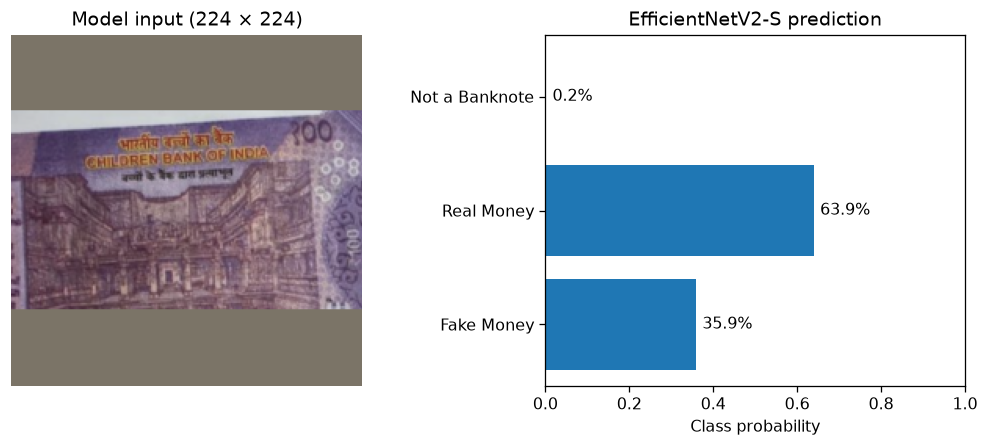

In [112]:
rgb_input = x[0].permute(1, 2, 0).cpu().numpy() * IMAGENET_STD + IMAGENET_MEAN
fig, (photo_ax, score_ax) = plt.subplots(1, 2, figsize=(9, 4))
photo_ax.imshow(np.clip(rgb_input, 0, 1))
photo_ax.set_title(f"Model input ({x.shape[-1]} × {x.shape[-2]})")
photo_ax.axis("off")
bars = score_ax.barh(names, probabilities)
score_ax.bar_label(bars, labels=[f"{p:.1%}" for p in probabilities], padding=4)
score_ax.set(xlim=(0, 1), xlabel="Class probability", title="EfficientNetV2-S prediction")
fig.tight_layout()
plt.show()

**What happened on the prediction?** The saved output shows 63.9% for Real Money, 35.9% for Fake Money and 0.2% for Not a Banknote. EfficientNetV2-S chose Real on the same photo as in Section 6.10. Against the dataset’s provisional Fake label, this counts as a missed fake.

Section 9 asks Grad-CAM and Score-CAM to explain the **Fake** score on this same photo. This lets us inspect where the model found a response for the class it missed. The prediction recorded here remains Real.

## 9. Show 2 XAI methods

Section 8 showed the classifier's decision. Here both methods explain the **Fake logit** (the raw Fake-class score before softmax), even when EfficientNetV2-S predicts Real. 

### 9.1 Recover the input photo

Undo the channel normalization in Section 8 since the heatmap will ignore manual padded part to increase explainability focus.

In [113]:
def input_rgb(x):
    """Undo ImageNet normalization to display the EfficientNetV2-S input."""
    rgb = x[0].permute(1, 2, 0).detach().cpu().numpy()
    return np.clip(rgb * IMAGENET_STD + IMAGENET_MEAN, 0, 1)


def valid_content_mask(geometry, shape):
    """Mark the photographic pixels inside the letterboxed input."""
    left, top, right, bottom = geometry["resized_coor"]
    mask = np.zeros(shape, dtype=bool)
    mask[top:bottom, left:right] = True
    return mask

### 9.2 Use Grad-CAM and Score-CAM for heatmap

Grad-CAM uses the gradient of the target score to weight feature maps. Score-CAM masks the input with activation maps and measures how the target responds in forward passes. The function returns a heatmap and cost time for either method. 

The two papers define the methods. The notebook directly calls the GradCAM and ScoreCAM classes from pytorch-grad-cam for this experiment. [Selvaraju et al., Grad-CAM](https://openaccess.thecvf.com/content_iccv_2017/html/Selvaraju_Grad-CAM_Visual_Explanations_ICCV_2017_paper.html) · [Wang et al., Score-CAM](https://openaccess.thecvf.com/content_CVPRW_2020/html/w1/Wang_Score-CAM_Score-Weighted_Visual_Explanations_for_Convolutional_Neural_Networks_CVPRW_2020_paper.html) · [Library implementation and usage](https://github.com/jacobgil/pytorch-grad-cam)

In [114]:
def generate_cam(model, x, target, method, batch_size):
    start = time.perf_counter()
    algorithm = {"gradcam": GradCAM, "scorecam": ScoreCAM}[method]
    use_grad = method == "gradcam"
    image = x.detach().requires_grad_(use_grad)
    with torch.set_grad_enabled(use_grad), algorithm(model=model, target_layers=[model.features[3]]) as cam:
        cam.batch_size = batch_size
        heatmap = cam(image, targets=[target])[0]
    model.zero_grad(set_to_none=True)
    return heatmap, time.perf_counter() - start

### 9.3 Overlay the heatmap on the image

Convert the heatmap to colors with OpenCV and blend it with the RGB input.

OpenCV supplies the colour map and weighted blend to display the heatmap. [applyColorMap](https://docs.opencv.org/4.x/d3/d50/group__imgproc__colormap.html) · [addWeighted](https://docs.opencv.org/4.x/d2/de8/group__core__array.html)

In [115]:
def cam_overlay(rgb, heatmap):
    """Color a CAM with OpenCV and blend it with the RGB image."""
    pixels = np.rint(np.clip(rgb, 0, 1) * 255).astype(np.uint8)
    intensity = np.rint(np.clip(heatmap, 0, 1) * 255).astype(np.uint8)
    colors = cv2.applyColorMap(intensity, cv2.COLORMAP_TURBO)
    colors = cv2.cvtColor(colors, cv2.COLOR_BGR2RGB)
    return cv2.addWeighted(pixels, 0.55, colors, 0.45, 0)

### 9.4 Show the original image and the two overlayed images with heatmaps

Read the panels from left to right. The time above each image is cost of time. A highlighted location is how EfficientNetV2-S considers it has sensative area to help its classification and it also serves as a candidate for the editing pixel test in Section 10.

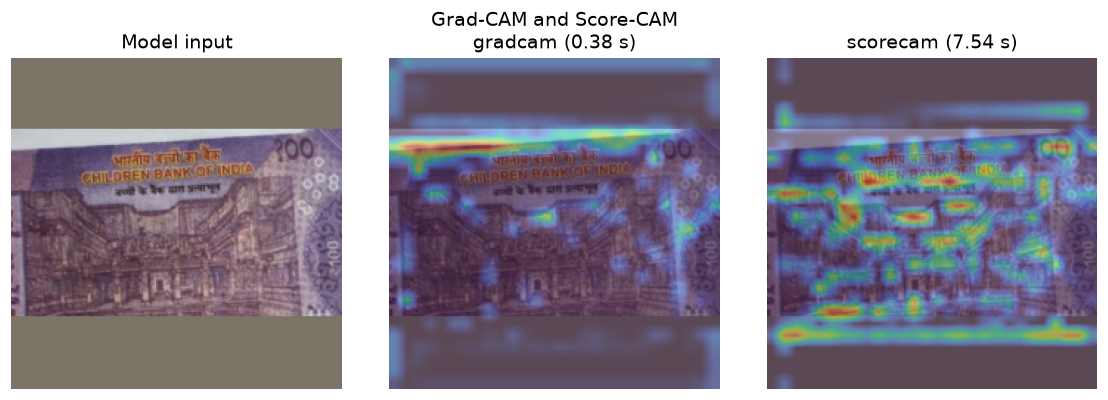

In [116]:
rgb = input_rgb(x)
valid = valid_content_mask(geometry, x.shape[-2:])
fake_target = ClassifierOutputTarget(CLASS_TO_IDX["fake money"])
heatmaps, flat = {}, {}

fig, axes = plt.subplots(1, len(METHODS) + 1, figsize=(10, 3.5))
axes[0].imshow(rgb)
axes[0].set_title("Model input")
for ax, method in zip(axes[1:], METHODS):
    heatmap, seconds = generate_cam(cam_model, x, fake_target, method, 16)
    heatmaps[method] = heatmap
    flat[method] = np.ptp(heatmap[valid]) < 1e-7
    ax.imshow(rgb if flat[method] else cam_overlay(rgb, heatmap))
    status = "flat map" if flat[method] else f"{seconds:.2f} s"
    ax.set_title(f"{method} ({status})")

for ax in axes:
    ax.axis("off")
fig.suptitle("Grad-CAM and Score-CAM")
fig.tight_layout()
plt.show()

## 10. Does editing the hottest part change the score?

On the 100-rupee photo, Grad-CAM highlights a strip along the upper edge. Score-CAM also highlights parts of the lettering and the printed design. How well do these maps locate pixels that affect the Fake score? The deletion and insertion tests from RISE evaluate the order of pixels across the photo. Section 11 returns to the wording itself. [RISE paper](https://arxiv.org/abs/1806.07421)

We use two tests described in the RISE paper. In **deletion**, we gradually cover the regions each heatmap highlights most strongly and track the model’s Fake probability. In **insertion**, we gradually restore those regions.

**AUC** is the area under each curve used by this paper as metrics as plots. The horizontal axis shows the fraction of the photo edited, and the vertical axis shows P(Fake) the probabilit that note is fake. A good editing order gives a low deletion AUC because the score falls early, and a high insertion AUC because the score recovers early.

### 10.1 Choose an editing order

Sorting every displayed pixel separately would give small differences of their own rank. Here we average the heat over neighbouring pixels so that a small patch receives one score. A 16 × 16 block is chosen for size, because smaller blocks would preserve finer detail. Larger blocks could mix the test "CHILDREN" with its surroundings to pollute the ranking.

`make_blocks` lists the pixels in each block and excludes padding. `ranked_pixels` visits the blocks from highest to lowest mean heat. `random_pixels` shuffles those same blocks.

In [117]:
def make_blocks(valid, block_size):
    height, width = valid.shape
    pixel_ids = np.arange(valid.size).reshape(valid.shape)
    pixel_ids[~valid] = -1
    blocks = []
    for y in range(0, height, block_size):
        for x in range(0, width, block_size):
            tile = pixel_ids[y:y + block_size, x:x + block_size]
            pixels = tile[tile >= 0]
            if pixels.size:
                blocks.append(pixels)
    return blocks


def ranked_pixels(heatmap, blocks):
    values = heatmap.ravel()
    hottest_first = sorted(blocks, key=lambda block: values[block].mean(), reverse=True)
    return np.concatenate(hottest_first)


def random_pixels(blocks, image_sha256, repeat, seed):
    rng = np.random.default_rng([seed, int(image_sha256[:8], 16), repeat])
    return np.concatenate([blocks[i] for i in rng.permutation(len(blocks))])

### 10.2 Prepare the image used to cover or restore

Deletion needs pixels to put in place of the original detail. Insertion needs a starting image with that detail removed. The same replacement serves both purposes. Here we fill the pixel area with 2 methods: 

1. Mean of colors: Section 10 uses the ImageNet mean colour (zero after normalization) and keep the padding fixed. 
2. The helper can also use a blurred copy of the photo to soften fine details and retain broad shapes. [OpenCV Gaussian blur](https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html)

In [118]:
def make_replacement(x, geometry, baseline, blur_kernel=31, blur_sigma=10):
    replacement = x.detach().clone()
    left, top, right, bottom = geometry["resized_coor"]
    content = replacement[0, :, top:bottom, left:right]
    if baseline == "mean":
        content.zero_()
    elif baseline == "blur":
        rgb = content.permute(1, 2, 0).cpu().numpy()
        blurred = cv2.GaussianBlur(rgb, (blur_kernel, blur_kernel), blur_sigma)
        content[:] = torch.from_numpy(blurred).permute(2, 0, 1)
    return replacement

### 10.3 Score the edited photos and measure the area under each curve

Suppose the photo has 1,000 ranked pixels. When fractions at 10%, cover the first 100 in the original image for deletion and restore those same 100 in the replacement for insertion. At 20%, keep the first edit and change the next 100 pixels in each image. After each step, run both images through EfficientNetV2-S and record the Fake probability.

`edit_curves` follows the [RISE authors’ deletion and insertion implementation](https://github.com/eclique/RISE/blob/master/evaluation.py#L55-L102). Adjustment occurs that I use the block order from Section 10.1 and keep the previous modification while the author modifies all. `curve_areas` uses the [trapezoid rule](https://numpy.org/doc/stable/reference/generated/numpy.trapezoid.html) to measure the area under each curve using the fraction of photo pixels actually edited. 

In [119]:
def edit_curves(model, x, replacement, pixel_order, fractions, original, reference, target_index, batch_size):
    """Edit the next ranked pixels at each step and record both target scores."""
    order = torch.as_tensor(pixel_order, device=x.device)
    counts = np.rint(fractions * len(order)).astype(int)
    deletion = x.clone()
    insertion = replacement.clone()

    photo_score = original["probabilities"][0][target_index]
    fill_score = reference["probabilities"][0][target_index]
    deleted = [photo_score]
    inserted = [fill_score]

    previous = 0
    for count in counts[1:-1]:
        # Keep earlier edits and change only the next group of pixels.
        positions = order[previous:count]
        deletion.flatten(2)[:, :, positions] = replacement.flatten(2)[:, :, positions]
        insertion.flatten(2)[:, :, positions] = x.flatten(2)[:, :, positions]
        scores = score_batches(model, torch.cat([deletion, insertion]), batch_size)["probabilities"]
        deleted.append(scores[0][target_index])
        inserted.append(scores[1][target_index])
        previous = count

    # At 100%, deletion reaches the replacement and insertion restores the photo.
    deleted.append(fill_score)
    inserted.append(photo_score)
    return pd.DataFrame({"Deletion": deleted, "Insertion": inserted}, index=counts / len(order))


def curve_areas(curves):
    return np.trapezoid(curves.to_numpy(), x=curves.index, axis=0)

### 10.4 Compare the 3 editing orders

The final cell runs the same experiment 3 times on the example image, one in random block order and one for each usable CAM. Read the left plot as “what happens when detail disappears?” and the right as “what happens when it returns?” Compare the methods at the same fraction on the horizontal axis. The table summarizes the full curves: lower deletion AUC and higher insertion AUC are better under this test. FlatMap for very similar adjucent ranking is skipped. 


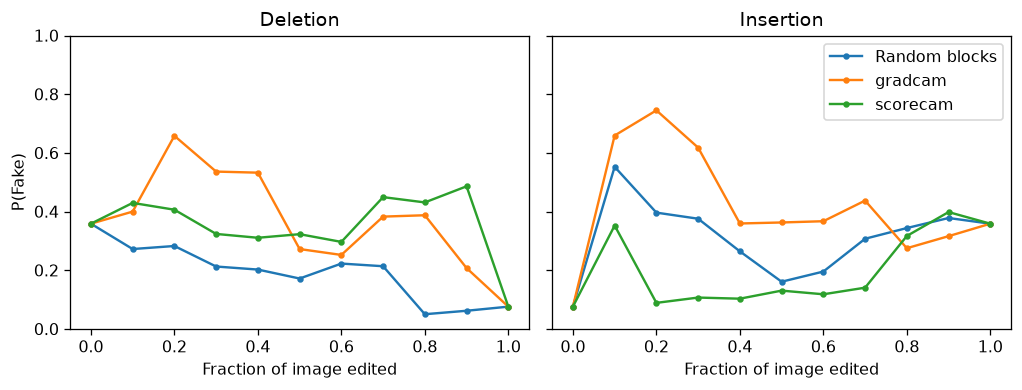

,Deletion AUC,Insertion AUC
Random blocks,0.191,0.319
gradcam,0.385,0.436
scorecam,0.368,0.197


In [120]:
blocks = make_blocks(valid, 16)
replacement = make_replacement(x, geometry, "mean")
reference = score_batches(cam_model, replacement, 16)
fractions = np.linspace(0, 1, 11)
orders = {"Random blocks": random_pixels(blocks, file_sha256(IMAGE), 0, 42)}
for method in METHODS:
    if not flat[method]:
        orders[method] = ranked_pixels(heatmaps[method], blocks)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
areas = {}
for method, order in orders.items():
    curves = edit_curves(cam_model, x, replacement, order, fractions, original, reference, 0, 16)
    areas[method] = curve_areas(curves)
    for ax, column in zip(axes, curves):
        ax.plot(curves.index, curves[column], marker=".", label=method)
for ax, column in zip(axes, ["Deletion", "Insertion"]):
    ax.set(title=column, xlabel="Fraction of image edited", ylim=(0, 1))
axes[0].set_ylabel("P(Fake)")
axes[1].legend()
fig.tight_layout()
plt.show()
display(pd.DataFrame.from_dict(areas, orient="index", columns=["Deletion AUC", "Insertion AUC"]).round(3))

**What happened on this image?** With mean-colour replacement, Grad-CAM scored 0.385 on deletion and 0.436 on insertion. Score-CAM scored 0.368 and 0.197, and random order scored 0.191 and 0.319. On this photo, random order had the lowest deletion AUC and Grad-CAM had the highest insertion AUC. These scores compare pixel rankings over the whole picture. A reviewer still needs to know why a Real prediction deserves a second look. The visible line of text gives us something specific to check.

## 11. Bridging the gap between the Model and XAI tools: Compare the visible text with the model decision

A reviewer can read a line near the top of the 100-rupee image to identify, but this is not feasible in the real world since billions of transactions are going on for each day. Thus, setting up an alarm mechanism is crucial in industry instead of just relying on manual check even if there's a Deep Learning software and a physical counterfeit money detector. We first transcribe the full photo, then compare a possible bank name with a published reference. Looking up the official issuer gives us an expected name before reading a new image. 

The OCR box lets the reviewer verify the transcription on the photo. The Fake-class heatmap and a local blur show how the classifier responds near that line.

### 11.1 Read the image before comparing names

The Reserve Bank of India lists ₹100 and ₹2000 among the denominations it issues. We use its English name, **Reserve Bank of India**, as the reference for these two examples. The name supplies the key word **BANK**. Read every line in the original image and print the raw OCR output for the 100-rupee example below. The recognition step receives only the image.

For the comparison, look for one OCR line containing the word BANK with a confidence of at least 0.5 though this cutoff value is a demonstration setting.[RBI currency FAQ, question 2](https://www.rbi.org.in/commonman/Upload/English/FAQs/PDFs/INDIANCURRENCY15042025.pdf) · [Apple Vision OCR interface](https://github.com/straussmaximilian/ocrmac)

In [ ]:
import re
from ocrmac import ocrmac

ISSUER = "RESERVE BANK OF INDIA"

def read_lines(path):
    """Read all English text lines with their confidence and location."""
    return ocrmac.OCR(str(path), language_preference=["en-US"]).recognize(px=True)

def issuer_candidate(lines):
    """Find one identifiable bank-name candidate and compare it with the reference."""
    candidates = []
    for text, confidence, box in lines:
        words = re.findall(r"[A-Z]+", text.upper())
        if confidence >= 0.5 and "BANK" in words:
            candidates.append((text, words, box))
    if len(candidates) != 1:
        return "unclear", None, None

    text, words, box = candidates[0]
    expected = ISSUER.split()
    if words == expected:
        status = "match"
    elif set(words) <= set(expected) or set(expected) <= set(words):
        # Missing, misordered or extra words can indicate as incomplete or unclear.
        status = "unclear"
    else:
        status = "different"
    return status, text, tuple(round(value) for value in box)

lines_100 = read_lines(IMAGE)
for text, confidence, _ in lines_100:
    print(f"{confidence:.2f}  {text}")

1.00  00
1.00  CHILDREN BANK OF INDIA


### 11.2 Turn the comparison into a review message

Show the text exactly as OCR read it. When the classifier chooses Real and the candidate differs from the official name, alarm the reviewer to inspect the box and compare the two names.

In [ ]:
def review_message(prediction, status, text):
    """Explain what the issuer comparison contributes to this decision."""
    if status == "unclear":
        # a potential future work can work on this scenario
        return "Insufficient text evidence to compare the issuer name."
    if status == "match":
        return f'OCR reads "{text}", match the issuer.'
    if prediction == "Real Money":
        return f'Review requested!!!!!! OCR reads "{text}". Expected issuer: {ISSUER}.'
    return f'OCR reads "{text}"!!!!! Compare the marked line with the issuer reference: {ISSUER}.'

**Test the marked line once.** Blur only the OCR box in the original image with an [OpenCV Gaussian blur](https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html). Run the edited photo through the same preprocessing and EfficientNetV2-S. Read the change in the Fake probability in percentage points. Blurring also changes nearby texture inside the box, so the measurement alone cannot prove that EfficientNetV2-S understood the letters. 

In [123]:
def blurred_fake_probability(photo, box):
    """Blur the detected line and score the edited photograph."""
    left, top, right, bottom = box
    edited = photo.copy()
    patch = photo[top:bottom, left:right]
    edited[top:bottom, left:right] = cv2.GaussianBlur(patch, (0, 0), sigmaX=8)
    pixels, _ = prepare_pixels(edited)
    batch = pixels.unsqueeze(0)
    return score_batches(cam_model, batch, 1)["probabilities"][0][CLASS_TO_IDX["fake money"]]

### 11.3 Read the review on two images

Look at the left-hand box to check that the candidate name is on the banknote. The middle panel puts the same OCR box on the Fake-class Score-CAM using the settings from Section 9. The last panel only leaves the name part so you can check the text. Under the figure, read the decision, the issuer comparison and the effect of blurring the box.

In [124]:
def show_review(path, heatmap, lines):
    """Display one model decision beside the visible wording and its local blur test."""
    photo = read_rgb(path)
    tensor, geometry = prepare_photo(path)
    probs = score_batches(cam_model, tensor, 1)["probabilities"][0]
    prediction = names[np.argmax(probs)]
    status, words, box = issuer_candidate(lines)

    left, top, right, bottom = geometry["resized_coor"]
    height, width = photo.shape[:2]
    photo_cam = cv2.resize(heatmap[top:bottom, left:right], (width, height))
    overlay = cam_overlay(photo / 255, photo_cam)
    fig, axes = plt.subplots(1, 3, figsize=(12, 3))
    if box:
        x1, y1, x2, y2 = box
    for ax, view, title in zip(axes[:2], [photo.copy(), overlay], ["Photograph", "Fake-class Score-CAM"]):
        if box:
            cv2.rectangle(view, (x1, y1), (x2-1, y2-1), (0, 235, 255), 3)
        ax.imshow(view)
        ax.set_title(title)
    axes[2].set_title("Wording read by OCR")
    if box:
        axes[2].imshow(photo[y1:y2, x1:x2])
    else:
        axes[2].text(0.5, 0.5, "No unique bank-name line", ha="center")
    for ax in axes:
        ax.axis("off")
    message = review_message(prediction, status, words)
    fig.suptitle(f"EfficientNetV2-S: {prediction} ({max(probs):.1%})\n{message}", fontsize=12)
    fig.tight_layout()
    plt.show()

    print(message)
    if box:
        before = probs[CLASS_TO_IDX["fake money"]]
        after = blurred_fake_probability(photo, box)
        print(f"Blurred wording box: P(Fake) {before:.1%} → {after:.1%} ({100*(after-before):+.1f} pp).")

**Compare the decisions.** Reuse the 100-rupee heatmap from Section 9. Compute the supplementary 2000-rupee pilot photo’s heatmap with the same checkpoint, layer and Fake target. Both photos carry a provisional Fake folder label. That label is used only to check the decisions afterwards.

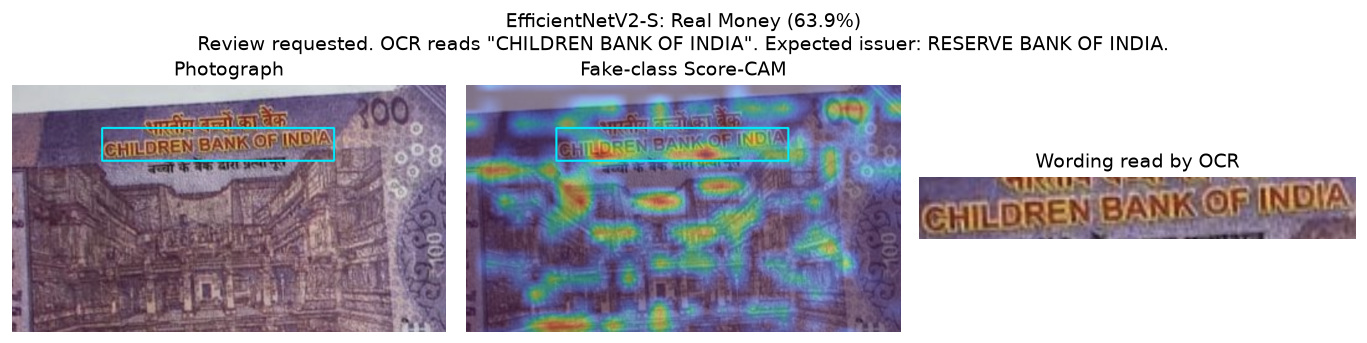

Review requested. OCR reads "CHILDREN BANK OF INDIA". Expected issuer: RESERVE BANK OF INDIA.
Blurred wording box: P(Fake) 35.9% → 27.8% (-8.0 pp).


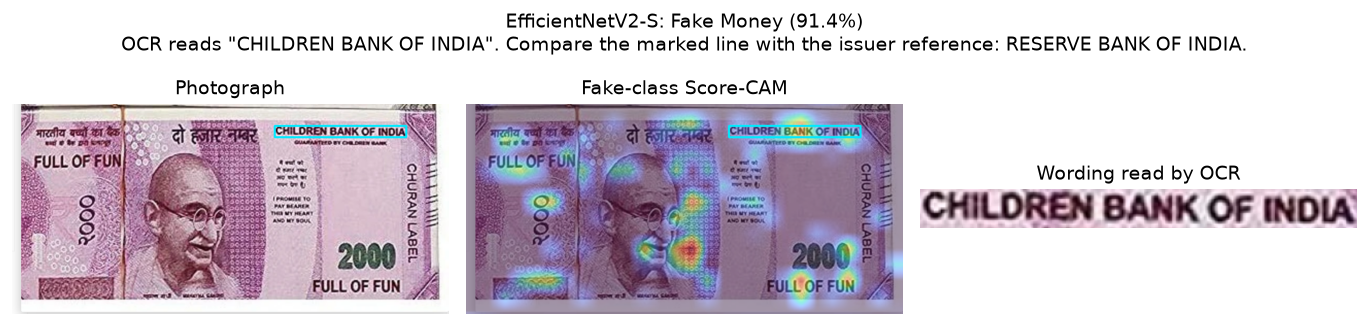

OCR reads "CHILDREN BANK OF INDIA". Compare the marked line with the issuer reference: RESERVE BANK OF INDIA.
Blurred wording box: P(Fake) 91.4% → 93.5% (+2.1 pp).


In [125]:
show_review(IMAGE, heatmaps["scorecam"], lines_100)

second_input, _ = prepare_photo(NOTE_2000)
second_cam, _ = generate_cam(cam_model, second_input, fake_target, "scorecam", 16)
show_review(NOTE_2000, second_cam, read_lines(NOTE_2000))

### 11.4 When does the wording justify a review?

**100 rupees.** EfficientNetV2-S chose Real (63.9%), but OCR read *CHILDREN BANK OF INDIA* where the expected issuer is *RESERVE BANK OF INDIA*. The alert gives the reviewer a line to inspect. Blurring its box lowered the Fake score from 35.9% to 27.8%. Under this edit, the original patch supported the Fake score, even though Real won on the full image.

**2000 rupees.** This second image illustrates what happens when the classifier already chooses Fake (91.4%), in agreement with the provisional folder label. OCR found the same issuer mismatch. The mismatch gives the reviewer a visible clue consistent with that decision. Blurring the box raised the Fake score to 93.5% (+2.1 percentage points), the opposite direction from the 100-rupee result. The same words are a reason for a person to inspect both notes, yet blurring the surrounding pixels affects the two predictions differently. The edit changes letters and texture together, so it cannot tell us that the model understood the words.

## 12. Project conclusion

**Classification.** I compared a CNN, ResNet18, EfficientNetV2-S and DINOv3 using the three classes Fake, Real and Not a Banknote. Our priority was catching fake-labelled notes while tracking how often genuine-labelled notes were flagged. On the same 53 test photos, EfficientNetV2-S averaged 90.6% accuracy and 93.1% Fake recall over three training seeds. It flagged 13.3% of Real-labelled photos as Fake. Despite its high recall, the seed-42 model STILL missed the 100-rupee example in Section 6.10.

**Explaining that miss.** Grad-CAM and Score-CAM highlighted different parts of the photo. We tested their rankings by removing and restoring image blocks. Grad-CAM recovered the Fake score fastest overall during insertion (AUC 0.436). Removing blocks in the sampled random order produced the lowest deletion AUC (0.191). Which ranking performed best depended on the test.

**What the project adds.** My review and alarm mechanism puts the prediction beside the printed issuer name, outlines what the OCR reading on the image in descriptive words and measures the change in the Fake score after an OpenCV Gaussian blur. On the 100-rupee photo, the reviewer can point to a specific word, *CHILDREN*, to explain why the Real decision deserves another look. The 2000-rupee example shows how the same wording can accompany a Fake decision.

A person familiar with Indian banknotes may notice a wording error on a banknote over a banknote seems to be easy. But in the real world, no financial institutions can assign a huge numbers ofstaff to inspect banknotes while equiping with software(DL method) and hardware(physical counterfeit money detector) support facing billions of transactions per day. The complete anaysis on this project will be discussed in the report, like why there's no existing DL method can gaurantee to find such texting errors(even DINO), pros and cons of what the project add, future work discussion, etc..